# H6 size-extensivity control

This notebook reproduces the paper's noninteracting-replica control. A linear H$_6$ unit with 1.55 Å spacing is built in STO-3G, transformed to its RHF molecular-orbital basis, and copied into exactly block-diagonal Hamiltonians for $N=1,\ldots,6$. Inter-unit one- and two-electron integrals are zero, so the exact result is additive by construction.

The notebook contains the actual Hamiltonian builder, FCIDUMP writer, FRASCI Parent call, and whole-system phased TrimCI call. `RECOMPUTE = False` loads frozen production values for a fast default run. Set it to `True` and select `NS_TO_RUN` to rerun points under `notebooks/runs/size_extensivity/`. The $N=6$ whole-system point uses 2.56 million determinants and is a production calculation, not an interactive demo.

Recovery is deliberately absent: a complete per-unit fragment already represents the exact separable product.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CWD = Path.cwd().resolve()
RELEASE_ROOT = next(
    candidate for candidate in (CWD, CWD.parent)
    if (candidate / "pyproject.toml").is_file()
    and (candidate / "frasci" / "__init__.py").is_file())

DATA_ROOT = RELEASE_ROOT / "notebooks" / "data"
RUN_ROOT = RELEASE_ROOT / "notebooks" / "runs" / "size_extensivity"
RECOMPUTE = False
NS_TO_RUN = ()  # e.g. (1, 2); use tuple(range(1, 7)) for the production ladder

paper = json.loads((DATA_ROOT / "paper_results.json").read_text())
frozen = paper["size_extensivity"]
print(f"Mode: {'recompute selected points' if RECOMPUTE else 'frozen paper records'}")

Mode: frozen paper records


## Build one physical H6 unit

The cell below constructs the physical unit and independently verifies its active-space FCI energy. It is intentionally separate from FRASCI and TrimCI.

In [2]:
def build_h6_unit(r_angstrom: float = 1.55):
    from pyscf import ao2mo, fci, gto, scf

    mol = gto.M(
        atom=[("H", (i * r_angstrom, 0.0, 0.0)) for i in range(6)],
        basis="sto-3g", unit="Angstrom", charge=0, spin=0, verbose=0)
    mf = scf.RHF(mol).run()
    coeff = mf.mo_coeff
    h1 = coeff.T @ mf.get_hcore() @ coeff
    eri = ao2mo.restore(1, ao2mo.kernel(mol, coeff), 6)
    e_fci, _ = fci.direct_spin1.kernel(h1, eri, 6, (3, 3), ecore=mol.energy_nuc())
    return h1, eri, float(mol.energy_nuc()), float(e_fci)


h1_unit, eri_unit, ecore_unit, e_fci_unit = build_h6_unit()
assert np.isclose(e_fci_unit, -2.973277626778038, atol=1e-11)
print(f"H6 unit FCI = {e_fci_unit:.15f} Ha")

H6 unit FCI = -2.973277626778040 Ha


## Construct exact block-diagonal replicas

`write_replica_fcidump` copies the unit one- and two-electron tensors onto diagonal orbital blocks and writes all other inter-unit integrals as zero. The scalar nuclear/core term is additive. The function therefore generates the Hamiltonian used in the control rather than reading a previously run result.

In [3]:
def block_diagonal_replicas(n_units: int):
    n_orb = 6 * n_units
    h1 = np.zeros((n_orb, n_orb))
    eri = np.zeros((n_orb, n_orb, n_orb, n_orb))
    for unit in range(n_units):
        s = slice(6 * unit, 6 * (unit + 1))
        h1[s, s] = h1_unit
        eri[s, s, s, s] = eri_unit
    return h1, eri, n_units * ecore_unit


def write_replica_fcidump(n_units: int, path: Path) -> Path:
    from pyscf.tools import fcidump

    h1, eri, ecore = block_diagonal_replicas(n_units)
    path.parent.mkdir(parents=True, exist_ok=True)
    fcidump.from_integrals(
        str(path), h1, eri, 6 * n_units, 6 * n_units,
        nuc=ecore, ms=0, orbsym=[1] * (6 * n_units), tol=1e-14)
    return path


# Structural check: every cross-unit two-electron block is exactly zero.
h1_2, eri_2, ecore_2 = block_diagonal_replicas(2)
assert np.count_nonzero(h1_2[:6, 6:]) == 0
assert np.count_nonzero(eri_2[:6, :, 6:, :]) == 0
assert ecore_2 == 2 * ecore_unit
print("Block-diagonal construction verified")

Block-diagonal construction verified


## Run the fragmented Parent and whole-system TrimCI

The Parent uses one complete `(6e,6o)` unit per fragment. Whole-system TrimCI uses four Phase-0 restarts, a 64-determinant discovery cap, a 1,000-determinant orbital-optimization cap, and the frozen-orbital Phase-2 support reported in the paper. All outputs are written to the ignored run directory.

The code path is fully present here, but the default execution does not launch multi-hour native calculations.

In [4]:
TRIMCI_PHASE2_DETS = {1: 400, 2: 80_000, 3: 80_000, 4: 640_000, 5: 640_000, 6: 2_560_000}


def run_replica_point(n_units: int) -> dict:
    import trimci
    from frasci.parent import ParentConfig, solve as solve_parent
    from frasci._trimci_config import build_coo_config, suppress_fd

    point_dir = RUN_ROOT / f"N{n_units}"
    fcidump_path = write_replica_fcidump(n_units, point_dir / "FCIDUMP")
    parent = solve_parent(
        str(fcidump_path),
        [list(range(6 * i, 6 * (i + 1))) for i in range(n_units)],
        [(3, 3)] * n_units,
        [1] * n_units,
        ParentConfig(
            threshold=1e-8, max_cycle_macro=30, orbopt=True, orbopt_cycles=5,
            phase0_dets=64, phase1_dets=400, discovery_num_runs=4,
            refine_num_runs=1, rng_seed=0),
        save_dets_to=point_dir / "parent")
    if not parent.converged:
        raise RuntimeError(f"N={n_units}: Parent did not converge")

    cfg = build_coo_config(
        threshold=1e-8, num_runs=4, orbopt=True, orbopt_cycles=5,
        max_dets_phase0=64, enable_phase1=True, max_dets_phase1=1000,
        growth_factor_phase1=1.1, enable_phase2=True,
        max_dets_phase2=TRIMCI_PHASE2_DETS[n_units],
        pt2=False, seed=0, save_fcidumps=False, verbosity=0)
    with suppress_fd(True):
        whole = trimci.ground_state_from_fcidump(str(fcidump_path), config=cfg)

    result = {
        "n_units": n_units,
        "lasscf_energy_ha": n_units * e_fci_unit,
        "parent_energy_ha": float(parent.e_tot),
        "whole_system_trimci_energy_ha": float(whole.energy),
        "whole_system_trimci_n_dets": int(whole.n_dets),
        "parent_converged": bool(parent.converged),
    }
    (point_dir / "result.json").write_text(json.dumps(result, indent=2) + "\n")
    return result


recomputed = {}
if RECOMPUTE:
    if not NS_TO_RUN:
        raise ValueError("Select NS_TO_RUN explicitly before launching production calculations")
    for n in NS_TO_RUN:
        recomputed[n] = run_replica_point(n)
        print(recomputed[n])
else:
    print("Recomputation skipped. Set RECOMPUTE=True and choose NS_TO_RUN to run points.")

Recomputation skipped. Set RECOMPUTE=True and choose NS_TO_RUN to run points.


## Production energies and size-extensivity error

For each method, the reported error is self-referenced to its own single-unit energy,

\[
\Delta E_{\mathrm{size}}(N) = \left|E(N)-N E(1)ight|.
\]

This tests additivity rather than absolute accuracy.

In [5]:
n = np.asarray(frozen["n_units"], dtype=int)
e_lasscf = np.asarray(frozen["lasscf_energy_ha"], dtype=float)
e_parent = np.asarray(frozen["parent_energy_ha"], dtype=float)
e_trimci = np.asarray(frozen["whole_system_trimci_energy_ha"], dtype=float)

def size_error_mha(energies):
    return 1000.0 * np.abs(energies - n * energies[0])

results = pd.DataFrame({
    "N": n,
    "LASSCF energy (Ha)": e_lasscf,
    "Parent energy (Ha)": e_parent,
    "whole TrimCI energy (Ha)": e_trimci,
    "LASSCF error (mHa)": size_error_mha(e_lasscf),
    "Parent error (mHa)": size_error_mha(e_parent),
    "whole TrimCI error (mHa)": size_error_mha(e_trimci),
    "TrimCI determinants": frozen["whole_system_trimci_phase2_dets"],
}).set_index("N")
results

   LASSCF energy (Ha)  ...  TrimCI determinants
N                      ...                     
1           -2.973278  ...                  400
2           -5.946555  ...                80000
3           -8.919833  ...                80000
4          -11.893111  ...               640000
5          -14.866388  ...               640000
6          -17.839666  ...              2560000

[6 rows x 7 columns]

## Paper graph

Exact or numerical zeros are shown at a `10^-6` mHa plotting floor. The floor affects only display, not the table above.

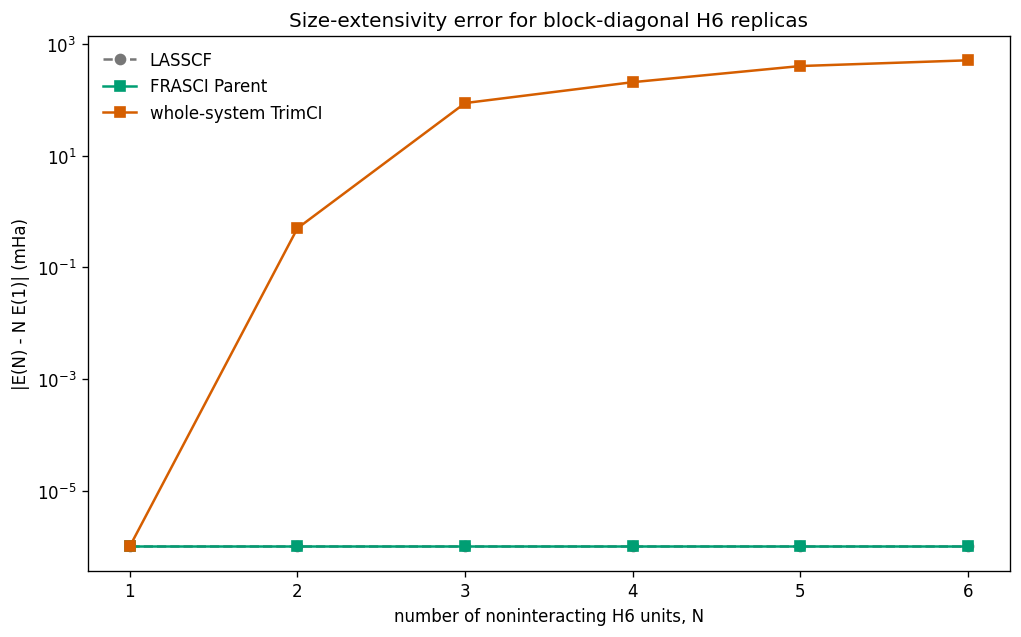

In [6]:
floor = 1e-6
fig, ax = plt.subplots(figsize=(8.4, 5.2), constrained_layout=True)
ax.plot(n, np.maximum(size_error_mha(e_lasscf), floor), "o--", color="#777777", label="LASSCF")
ax.plot(n, np.maximum(size_error_mha(e_parent), floor), "s-", color="#009E73", label="FRASCI Parent")
ax.plot(n, np.maximum(size_error_mha(e_trimci), floor), "s-", color="#D55E00", label="whole-system TrimCI")
ax.set_yscale("log")
ax.set_xticks(n)
ax.set_xlabel("number of noninteracting H6 units, N")
ax.set_ylabel("|E(N) - N E(1)| (mHa)")
ax.set_title("Size-extensivity error for block-diagonal H6 replicas")
ax.legend(frameon=False)
plt.show()

## Interpretation

The LASSCF and FRASCI Parent traces remain at numerical zero because each complete H6 unit is retained as one fragment state inside a contracted product. The whole-system selected-CI calculation must rediscover an increasingly large product support and shows a growing finite-budget error despite the larger determinant caps.

This control establishes Parent-side size consistency for an exactly separated Hamiltonian. It does not test finite Recovery, interacting replicas, or an asymptotic scaling law for TrimCI.